In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import idx2numpy
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [2]:
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

if project_root not in sys.path:
    sys.path.append(project_root)

In [ ]:
from mlp_model.losses.cce_loss import CCELoss
from mlp_model.activations.relu import ReLU
import visualisation.classification_visualise as cl_vs
import classification_training_methods as cl_train

In [4]:
train_images_filepath = Path(project_root) / "data/mnist/train" / "train-images-idx3-ubyte"
train_labels_filepath = Path(project_root) / "data/mnist/train" / "train-labels-idx1-ubyte"

In [5]:
X = idx2numpy.convert_from_file(str(train_images_filepath))
y = idx2numpy.convert_from_file(str(train_labels_filepath))

In [6]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [7]:
X_train = X_train.reshape(X_train.shape[0], -1).astype(np.float32) / 255.0
X_val = X_val.reshape(X_val.shape[0], -1).astype(np.float32) / 255.0

## Architektura 784-512-512-256-128-10, seed=42, batch_size=32, funkcja aktywacji ReLU, funkcja straty CCE, epochs=30

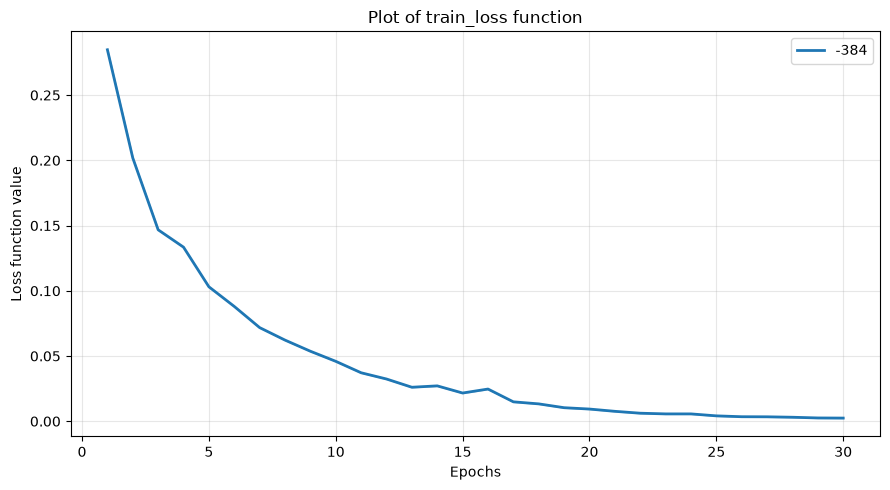

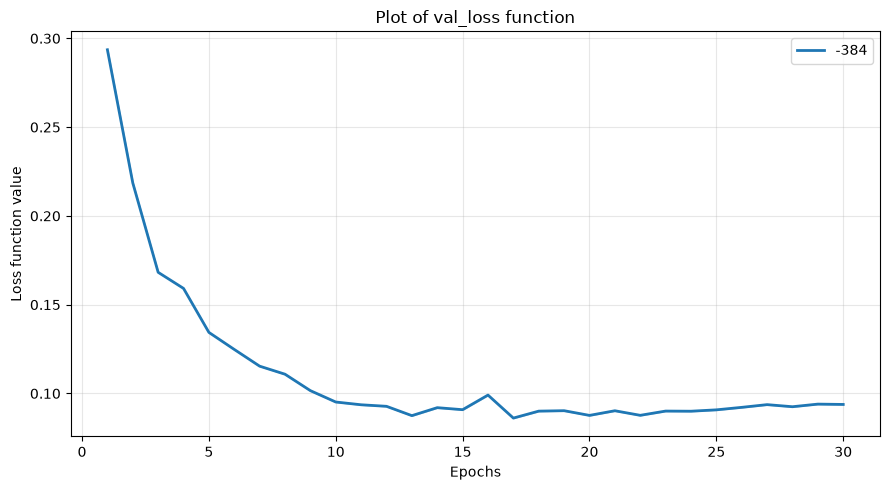

,config,loss_mean,loss_std,accuracy_mean,accuracy_std,precision_mean,precision_std,f1_score_mean,f1_score_std
0,-384,0.093801,0.0,0.979167,0.0,0.978976,0.0,0.978972,0.0


In [ ]:
trainings = {}

trainings["512-512-256-128"] = cl_train.run_training(hidden_sizes=(512, 512, 256, 128), X_train=X_train, y_train=y_train, X_val=X_val,
                                            y_val=y_val, activation_hidden=ReLU(), epochs=30, seeds=(42,),
                                            loss_cls=CCELoss(), learning_rate=0.01, classes_count=10)

cl_vs.plot_loss(trainings, "train_loss")
cl_vs.plot_loss(trainings, "val_loss")

display(cl_train.summarize_results(trainings))

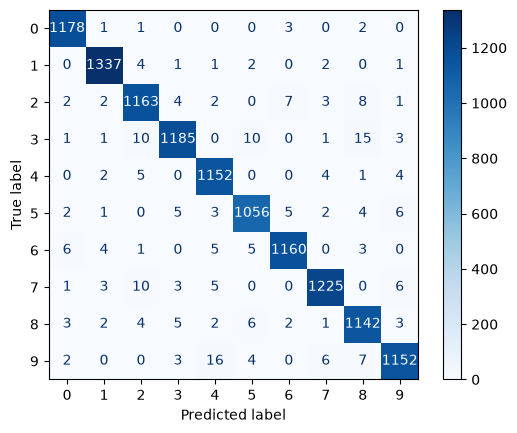

In [ ]:
trainer = trainings["512-512-256-128"][0]["trainer"]
y_preds = trainer.predict(X_val)

if y_preds.ndim == 2:
    y_preds = np.argmax(y_preds, axis=1)

cl_vs.plot_confussion_matrix(y_val, y_preds)

## Ewaluacja na zbiorze testowym

In [11]:
test_images_filepath = Path(project_root) / "data/mnist/test" / "t10k-images.idx3-ubyte"
test_labels_filepath = Path(project_root) / "data/mnist/test" / "t10k-labels.idx1-ubyte"

In [12]:
X_test = idx2numpy.convert_from_file(str(test_images_filepath))
y_test = idx2numpy.convert_from_file(str(test_labels_filepath))

In [13]:
X_test.shape

(10000, 28, 28)

In [14]:
X_test = X_test.reshape(X_test.shape[0], -1).astype(np.float32) / 255.0

In [15]:
X_test.shape

(10000, 784)

In [ ]:
test_results = cl_train.evaluate_runs(trainings["512-512-256-128"], X_test, y_test)
display(test_results)

,seed,test_loss,accuracy,precision,f1_score
0,42,0.083033,0.9786,0.978571,0.978455
